In [9]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

In [2]:
df = pd.read_csv('cleaned_survey_data.csv')

In [3]:
df.head(2)

,EdLevel,WorkExp,DevType,OrgSize,RemoteWork,Country,LanguageHaveWorkedWith,ConvertedCompYearly,lang_JavaScript,lang_SQL,...,lang_Kotlin,lang_Lua,lang_Swift,lang_Visual Basic (.Net),lang_R,lang_Groovy,lang_Assembly,lang_Perl,lang_others,DevType_grouped
0,Some college/university study without earning ...,7.0,"Developer, full-stack",100 to 499 employees,Remote,United States of America,C#;C++;JavaScript;Python;Visual Basic (.Net),87500.0,1,0,...,0,0,0,1,0,0,0,0,0,"Developer, full-stack"
1,"Master’s degree (M.A., M.S., M.Eng., MBA, etc.)",19.0,"Developer, mobile",500 to 999 employees,Remote,United States of America,Bash/Shell (all shells);C;C#;C++;Java;JavaScri...,205000.0,1,1,...,1,0,1,0,0,0,0,0,0,"Developer, mobile"


In [7]:
corr_matrix = df.corr()
print(corr_matrix['ConvertedCompYearly'].sort_values(ascending=False))

ConvertedCompYearly             1.000000
WorkExp                         0.195103
lang_Go                         0.154691
lang_Java                       0.086191
lang_Ruby                       0.081344
lang_Kotlin                     0.076737
lang_Rust                       0.073960
lang_Python                     0.060507
lang_TypeScript                 0.058338
lang_Assembly                   0.056636
lang_Swift                      0.053054
lang_Bash/Shell (all shells)    0.051673
lang_Groovy                     0.042350
lang_Perl                       0.030364
lang_C++                        0.027943
lang_Lua                        0.022670
lang_C                          0.015290
lang_others                    -0.001982
lang_SQL                       -0.051941
lang_R                         -0.060424
lang_JavaScript                -0.068605
lang_PHP                       -0.107908
lang_C#                        -0.115169
lang_PowerShell                -0.115550
lang_Visual Basi

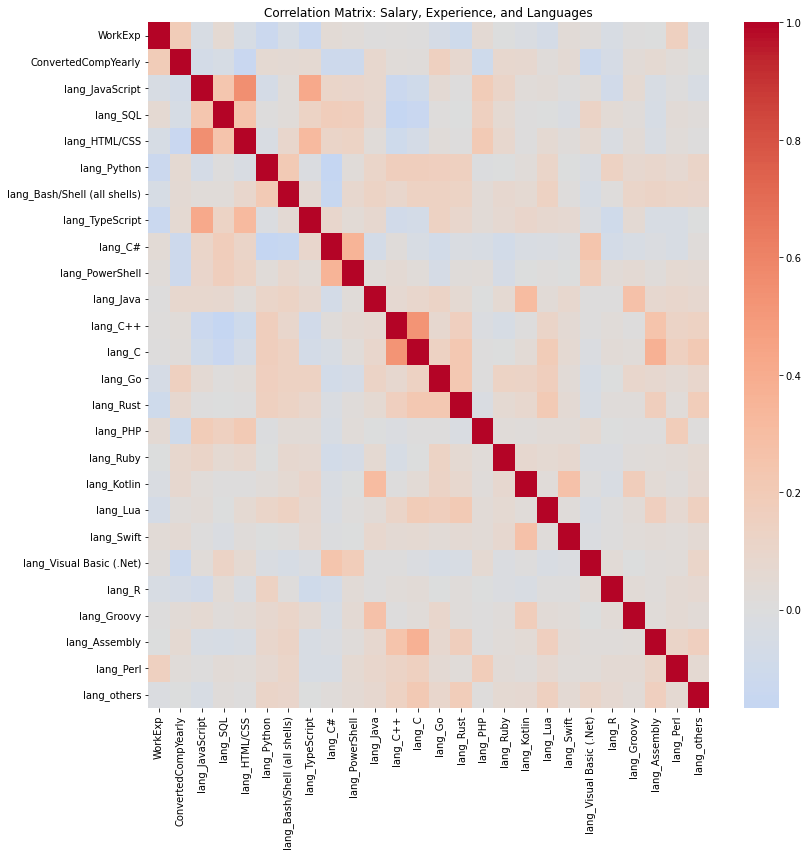

In [10]:
plt.figure(figsize=(12, 12))
sns.heatmap(corr_matrix, annot=False, cmap='coolwarm', center=0)
plt.title('Correlation Matrix: Salary, Experience, and Languages')
plt.tight_layout()
plt.savefig('correlation_heatmap.png', dpi=150)
plt.show()

### Handling the skew (log-transform the target)

In [14]:
df['log_salary'] = np.log(df['ConvertedCompYearly']).copy()

In [16]:
import statsmodels.formula.api as smf

model = smf.ols(
    'log_salary ~ WorkExp + C(DevType_grouped) + C(RemoteWork) + C(OrgSize) + C(EdLevel) + '
    'lang_Python + lang_JavaScript + lang_SQL + lang_Go + lang_Java + lang_TypeScript',
    data=df
).fit()
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:             log_salary   R-squared:                       0.273
Model:                            OLS   Adj. R-squared:                  0.266
Method:                 Least Squares   F-statistic:                     42.14
Date:                Sun, 23 Aug 2026   Prob (F-statistic):          1.82e-282
Time:                        16:20:19   Log-Likelihood:                -2547.0
No. Observations:                4652   AIC:                             5178.
Df Residuals:                    4610   BIC:                             5449.
Df Model:                          41                                         
Covariance Type:            nonrobust                                         
                                                                                                       coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------

0.0118 × 100 ~ 1.18% increase in salary per additional year of experience, holding everything else (role, org size, education, languages) constant.

Experience matters (1.18%/year, highly significant), but its raw, unadjusted appearance of dominance in the simple SQL table was partly inflated by confounding with role and company size. Meanwhile, specific high-value skills (Go, TypeScript) show effects nearly as strong or stronger than a full year of additional experience, and organizational factors (size, remote-work arrangement) rival or exceed experience's influence entirely.

In [18]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

import patsy
y, X = patsy.dmatrices(
    'log_salary ~ WorkExp + C(DevType_grouped) + C(RemoteWork) + C(OrgSize) + C(EdLevel) + '
    'lang_Python + lang_JavaScript + lang_SQL + lang_Go + lang_Java + lang_TypeScript',
    data=df, return_type='dataframe'
)

vif_data = pd.DataFrame()
vif_data['variable'] = X.columns
vif_data['VIF'] = [variance_inflation_factor(X.values, i) for i in range(X.shape[1])]
print(vif_data.sort_values('VIF', ascending=False))

                                             variable         VIF
0                                           Intercept  110.832049
17                           C(RemoteWork)[T.Unknown]   17.760504
27                              C(OrgSize)[T.Unknown]   17.662124
10        C(DevType_grouped)[T.Developer, full-stack]   15.911636
13                        C(DevType_grouped)[T.Other]   10.519272
6           C(DevType_grouped)[T.Developer, back-end]    8.717043
28  C(EdLevel)[T.Bachelor’s degree (B.A., B.S., B....    5.810106
1   C(DevType_grouped)[T.Architect, software or so...    5.093363
29  C(EdLevel)[T.Master’s degree (M.A., M.S., M.En...    4.361845
7   C(DevType_grouped)[T.Developer, desktop or ent...    4.321679
12          C(DevType_grouped)[T.Engineering manager]    3.814848
9          C(DevType_grouped)[T.Developer, front-end]    3.692779
8   C(DevType_grouped)[T.Developer, embedded appli...    3.278623
34  C(EdLevel)[T.Some college/university study wit...    3.123458
5   C(DevT

C:\ProgramData\Anaconda3\lib\site-packages\statsmodels\graphics\gofplots.py:993: UserWarning: marker is redundantly defined by the 'marker' keyword argument and the fmt string "bo" (-> marker='o'). The keyword argument will take precedence.
  ax.plot(x, y, fmt, **plot_style)


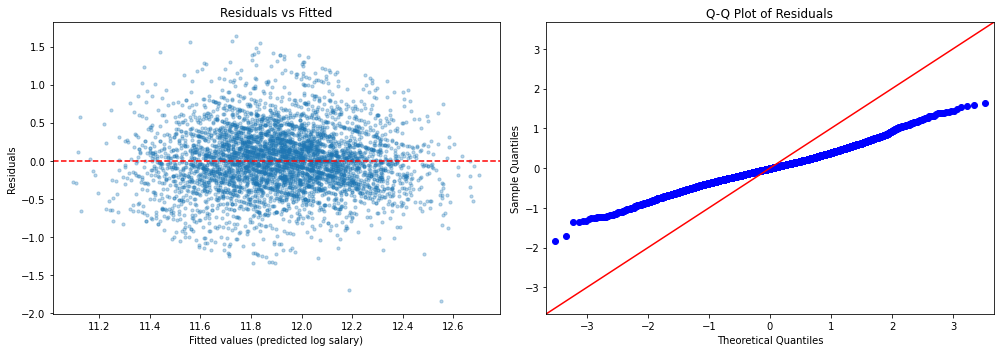

In [19]:
residuals = model.resid
fitted = model.fittedvalues

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Residuals vs Fitted — checking for patterns/heteroscedasticity
axes[0].scatter(fitted, residuals, alpha=0.3, s=10)
axes[0].axhline(y=0, color='red', linestyle='--')
axes[0].set_xlabel('Fitted values (predicted log salary)')
axes[0].set_ylabel('Residuals')
axes[0].set_title('Residuals vs Fitted')

# Plot 2: Q-Q plot — checking normality of residuals
import statsmodels.api as sm
sm.qqplot(residuals, line='45', ax=axes[1])
axes[1].set_title('Q-Q Plot of Residuals')

plt.tight_layout()
plt.savefig('residual_diagnostics.png', dpi=150)
plt.show()